<a href="https://colab.research.google.com/github/Don4141/ProductPriceAI/blob/main/Data_Curation_and_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mount google drive

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


Verify Colab can retrieve your GitHub secret

In [2]:
from google.colab import userdata
github_token = userdata.get("GITHUB_TOKEN")
print("Github token added", github_token is not None)

Github token added True


In [3]:
import os
os.chdir("/content")
#Clone repo after a new Colab runtime as the previous will be erased
!git clone https://github.com/Don4141/ProductPriceAI.git

#Set repository as working directory
os.chdir("/content/ProductPriceAI")

#Verify
print("Repo exist", os.path.exists("/content/ProductPriceAI"))
print("Current working directory", os.getcwd())

Cloning into 'ProductPriceAI'...
remote: Enumerating objects: 41, done.
remote: Counting objects: 100% (41/41), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 41 (delta 16), reused 20 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (41/41), 25.48 KiB | 243.00 KiB/s, done.
Resolving deltas: 100% (16/16), done.
Repo exist True
Current working directory /content/ProductPriceAI


Setup Colab environment variables

In [ ]:
import stat
from pathlib import Path
from google.colab import userdata
from huggingface_hub import login
from datasets import load_dataset, concatenate_datasets
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import json
import re
from collections import Counter
import numpy as np
import random
from pricer.loaders import ItemLoader
from pricer.items import Item #from the pricer package, open the items module(items.py) and import the Item class
from pricer.parser import parse #from the pricer package, open the parser module(parser.py) and import the parser class

The goal of this project is to build a model that predicts product prices based on their textual descriptions. The dataset was curated from the Amazon Reviews 2023 dataset, available on Hugging Face. Eight product categories were selected for analysis, as listed below.

Dataset: https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/tree/main/raw/meta_categories  

In [ ]:
dataset_names = [
    "Automotive",
    "Electronics",
    "Office_Products",
    "Tools_and_Home_Improvement",
    "Cell_Phones_and_Accessories",
    "Toys_and_Games",
    "Appliances",
    "Musical_Instruments"
]

Let's examine the Automotive product category from the Amazon dataset to understand the data structure, feature types, and attributes associated with each product.

In [ ]:
DATASET_REPO = "McAuley-Lab/Amazon-Reviews-2023"
DATASET_REVISION = "d0a762100fdcf7e420bab24f4bb9179876a0222f"

category = "Automotive"
raw_dataset = load_dataset(
    "parquet",
    data_files={
        "full": (
            f"hf://datasets/{DATASET_REPO}@{DATASET_REVISION}/"
            f"raw_meta_{category}/*.parquet"
        )
    },
    split="full"
)

raw_meta_Automotive/full-00000-of-00010.(…): reconstructing file:   0%|          |  0.00B /  206MB            

raw_meta_Automotive/full-00000-of-00010.(…): downloading bytes:           |  0.00B            

raw_meta_Automotive/full-00001-of-00010.(…): reconstructing file:   0%|          |  0.00B /  202MB            

raw_meta_Automotive/full-00001-of-00010.(…): downloading bytes:           |  0.00B            

raw_meta_Automotive/full-00002-of-00010.(…): reconstructing file:   0%|          |  0.00B /  200MB            

...

raw_meta_Automotive/full-00008-of-00010.(…): reconstructing file:   0%|          |  0.00B /  182MB            

raw_meta_Automotive/full-00008-of-00010.(…): downloading bytes:           |  0.00B            

raw_meta_Automotive/full-00009-of-00010.(…): reconstructing file:   0%|          |  0.00B /  179MB            

raw_meta_Automotive/full-00009-of-00010.(…): downloading bytes:           |  0.00B            

Generating full split: 0 examples [00:00, ? examples/s]

What data types are assigned to each feature (column) in the Hugging Face dataset?

In [ ]:
for feature, datatype in raw_dataset.features.items():
    print(f"{feature}: {datatype}")

main_category: Value('string')
title: Value('string')
average_rating: Value('float64')
rating_number: Value('int64')
features: List(Value('string'))
description: List(Value('string'))
price: Value('string')
images: {'hi_res': List(Value('string')), 'large': List(Value('string')), 'thumb': List(Value('string')), 'variant': List(Value('string'))}
videos: {'title': List(Value('string')), 'url': List(Value('string')), 'user_id': List(Value('string'))}
store: Value('string')
categories: List(Value('string'))
details: Value('string')
parent_asin: Value('string')
bought_together: Value('string')
subtitle: Value('string')
author: Value('string')


How many price values can be successfully converted to numeric values? What invalid or non-numeric price representations exist, and how frequently does each occur? Are any price values missing, and how are they represented in the dataset?

In [ ]:
prices = raw_dataset["price"]

valid_prices = 0
invalid_prices = {}

for price in prices:
    try:
        float(price)
        valid_prices += 1

    except (ValueError, TypeError):
        invalid_prices[price] = invalid_prices.get(price, 0) + 1

print(f"Valid numeric prices: {valid_prices:,}")
print(f"Invalid prices: {invalid_prices}")

Valid numeric prices: 1,131,970
Invalid prices: {'None': 871074, '—': 72, 'from 34.95': 2, 'from 68.67': 1, 'from 32.95': 1, 'from 25.00': 1, 'from 43.33': 1, 'from 24.95': 1, 'from 4.16': 1, 'from 48.69': 1, 'from 42.95': 1, 'from 46.88': 1, 'from 9.88': 1, 'from 4.95': 1}


 The dataset contains items with missing prices represented as the string `"None"` rather than Python's `None` object.

 ---


Let's examine the text-related attributes (`title`, `description`, `features`, and `details`) to identify any missing values.


In [ ]:
missing_title = 0
missing_description = 0
missing_features = 0
missing_details = 0

for item in tqdm(raw_dataset):

    # title is a string
    if not item["title"]:
        missing_title += 1

    # description is a list
    if not item["description"]:
        missing_description += 1

    # features is a list
    if not item["features"]:
        missing_features += 1

    # details is a JSON string
    details = item["details"]

    if not details or details == "None" or details == "{}":
        missing_details += 1

total = len(raw_dataset)
print(f"\nMissing title: {missing_title:,} ({missing_title / total * 100:.2f}%)")
print(f"Missing description: {missing_description:,} ({missing_description / total * 100:.2f}%)")
print(f"Missing features: {missing_features:,} ({missing_features / total * 100:.2f}%)")
print(f"Missing details: {missing_details:,} ({missing_details / total * 100:.2f}%)")

100%|██████████| 2003129/2003129 [06:00<00:00, 5560.40it/s]


Missing title:       93 (0.00%)
Missing description: 673,669 (33.63%)
Missing features:    307,712 (15.36%)
Missing details:     32,898 (1.64%)


Let's examine the dataset to identify potential duplicate products based on their titles.

In [ ]:
from collections import Counter

titles = tqdm(raw_dataset["title"])

title_counts = Counter(titles)

duplicate_titles = {
    title: count
    for title, count in title_counts.items()
    if count > 1
}

print(f"Total products: {len(raw_dataset):,}")
print(f"Unique titles: {len(title_counts):,}")
print(f"Titles appearing more than once: {len(duplicate_titles):,}")

100%|██████████| 2003129/2003129 [00:30<00:00, 65080.31it/s]


Total products: 2,003,129
Unique titles: 1,954,611
Titles appearing more than once: 32,307


 The dataset can contain duplicate product entries.

---

Products may share identical titles while representing different variants. Let's examine one of these duplicated titles and compare the corresponding product records.

In [ ]:
example_title = next(iter(duplicate_titles))

print(f"Investigating: {example_title}\n")

matches = raw_dataset.filter(
    lambda item: item["title"] == example_title
)

for item in matches:
    print(f"Title: {item['title']}")
    print(f"Price: {item['price']}")
    print(f"Description: {item['description']}")
    print(f"Features: {item['features']}")
    print(f"Details: {item['details']}")
    print(f"Parent ASIN: {item['parent_asin']}")
    print("-" * 100)

Investigating: NewYall Hood Latch Lock



Filter:   0%|          | 0/2003129 [00:00<?, ? examples/s]

Title: NewYall Hood Latch Lock
Price: 27.98
Description: ['For Hyundai Sonata Sedan 2015-2017']
Features: ['For Hyundai Sonata Sedan 2015-2017']
Details: {"Manufacturer": "NewYall", "Brand": "NewYall", "Model": "8ll30-Cll00", "Item Weight": "1.23 pounds", "Package Dimensions": "7.91 x 5.35 x 4.29 inches", "Country of Origin": "China", "Item model number": "8ll30-Cll00", "Exterior": "other", "Manufacturer Part Number": "8ll30-Cll00", "Best Sellers Rank": {"Automotive": 225369, "Automotive Hoods": 249}, "Date First Available": "August 31, 2021", "Style": "Modern", "Color": "Black", "Number of Pieces": "1"}
Parent ASIN: B09F3FKL62
----------------------------------------------------------------------------------------------------
Title: NewYall Hood Latch Lock
Price: 14.14
Description: ['For Toyota Highlander Sport Utility 2008-2010']
Features: ['For Toyota Highlander Sport Utility 2008-2010']
Details: {"Manufacturer": "NewYall", "Brand": "NewYall", "Model": "535l0-48l84", "Item Weight": 

This demonstrates that products with identical titles are not necessarily duplicates.

---

In [ ]:
# ---------------------------------------------
# Helper function to clean unnecessary whitespace
# ---------------------------------------------

def clean_text(text):
    if not text:
        return ""

    text = str(text)

    # Replace repeated whitespace with one space
    text = re.sub(r"\s+", " ", text)

    return text.strip()


# ---------------------------------------------
# Variables for storing the analysis
# ---------------------------------------------

total_products = len(raw_dataset)

title_in_description = 0
title_in_features = 0

products_with_duplicate_features = 0
total_duplicate_features = 0

total_details_fields = 0
details_fields_repeated_elsewhere = 0

results = []


# ---------------------------------------------
# Analyze each product
# ---------------------------------------------

for item in tqdm(raw_dataset):

    # =========================================
    # 1. CLEAN TITLE
    # =========================================

    title_text = clean_text(item["title"])


    # =========================================
    # 2. CLEAN DESCRIPTION
    # =========================================

    description = item["description"]

    if description:
        description_text = " ".join(
            clean_text(x)
            for x in description
            if x
        )
    else:
        description_text = ""

    description_text = clean_text(description_text)


    # =========================================
    # 3. CLEAN FEATURES
    # =========================================

    features = item["features"]

    if features:
        cleaned_features = [
            clean_text(x)
            for x in features
            if x
        ]
    else:
        cleaned_features = []

    features_text = " ".join(cleaned_features)
    features_text = clean_text(features_text)


    # =========================================
    # 4. CLEAN DETAILS
    # =========================================

    details = item["details"]

    if details and details != "None":
        try:
            details_dict = json.loads(details)
        except (json.JSONDecodeError, TypeError):
            details_dict = {}
    else:
        details_dict = {}


    # =========================================
    # 5. IS TITLE REPEATED IN DESCRIPTION?
    # =========================================

    title_repeated_description = False

    if title_text and description_text:

        if title_text.lower() in description_text.lower():
            title_repeated_description = True
            title_in_description += 1


    # =========================================
    # 6. IS TITLE REPEATED IN FEATURES?
    # =========================================

    title_repeated_features = False

    if title_text and features_text:

        if title_text.lower() in features_text.lower():
            title_repeated_features = True
            title_in_features += 1


    # =========================================
    # 7. COUNT DUPLICATE FEATURES
    # =========================================

    seen_features = set()
    duplicate_features = 0

    for feature in cleaned_features:

        normalized_feature = feature.lower()

        if normalized_feature in seen_features:
            duplicate_features += 1
        else:
            seen_features.add(normalized_feature)

    if duplicate_features > 0:
        products_with_duplicate_features += 1
        total_duplicate_features += duplicate_features


    # =========================================
    # 8. CHECK WHETHER DETAILS ARE REPEATED
    #    ELSEWHERE
    # =========================================

    other_text = " ".join([
        title_text,
        description_text,
        features_text
    ])

    other_text = clean_text(other_text).lower()

    product_details_count = 0
    product_details_repeated = 0

    for key, value in details_dict.items():

        key_text = clean_text(key)
        value_text = clean_text(value)

        if not value_text:
            continue

        product_details_count += 1
        total_details_fields += 1

        # Check whether the detail value already appears
        # in title + description + features
        if value_text.lower() in other_text:
            product_details_repeated += 1
            details_fields_repeated_elsewhere += 1


    # =========================================
    # 9. CALCULATE PRODUCT-LEVEL DETAILS OVERLAP
    # =========================================

    if product_details_count > 0:
        details_overlap_ratio = (
            product_details_repeated /
            product_details_count
        )
    else:
        details_overlap_ratio = 0


    # =========================================
    # 10. SAVE PRODUCT-LEVEL RESULTS
    # =========================================

    results.append({
        "title": title_text,
        "title_in_description": title_repeated_description,
        "title_in_features": title_repeated_features,
        "duplicate_features": duplicate_features,
        "details_count": product_details_count,
        "details_repeated": product_details_repeated,
        "details_overlap_ratio": details_overlap_ratio
    })


# ---------------------------------------------
# Overall results
# ---------------------------------------------

print(f"\nTotal products: {total_products:,}")

print(
    f"\nTitle repeated in description: "
    f"{title_in_description:,} "
    f"({title_in_description / total_products * 100:.2f}%)"
)

print(
    f"Title repeated in features: "
    f"{title_in_features:,} "
    f"({title_in_features / total_products * 100:.2f}%)"
)

print(
    f"\nProducts with duplicate features: "
    f"{products_with_duplicate_features:,} "
    f"({products_with_duplicate_features / total_products * 100:.2f}%)"
)

print(
    f"Total duplicate feature entries: "
    f"{total_duplicate_features:,}"
)

print(
    f"\nTotal detail fields analyzed: "
    f"{total_details_fields:,}"
)

print(
    f"Detail values repeated in title/description/features: "
    f"{details_fields_repeated_elsewhere:,}"
)

if total_details_fields > 0:
    print(
        f"Overall details overlap: "
        f"{details_fields_repeated_elsewhere / total_details_fields * 100:.2f}%"
    )

100%|██████████| 2003129/2003129 [16:19<00:00, 2044.81it/s]


Total products: 2,003,129

Title repeated in description: 53,631 (2.68%)
Title repeated in features: 16,062 (0.80%)

Products with duplicate features: 18,053 (0.90%)
Total duplicate feature entries: 31,495

Total detail fields analyzed: 21,632,550
Detail values repeated in title/description/features: 7,060,581
Overall details overlap: 32.64%


Out of the 2,003,129 products analyzed, 2.68% have their full titles repeated in the descriptions, while 0.80% have their titles repeated in the features. Additionally, 0.90% of products contain duplicate feature entries, with 31,495 duplicate entries identified in total. Among the 21,632,550 detail fields analyzed, 32.64% have values that also appear verbatim in the combined title, description, and features text.

---

For each product, let's combine the title, description, features, and details into a single text representation and calculate its total character length. We'll then examine the distribution of text lengths and compute summary statistics to understand the amount of textual information available across products.

In [ ]:
def analyze_combined_text_lengths(dataset):
    """
    Combine title, description, features, and details for each product,
    normalize whitespace, calculate character lengths, and summarize
    the length distribution.
    """

    combined_lengths = []

    for item in tqdm(dataset):

        # Convert the four attributes to text
        title = item["title"] or ""
        description = " ".join(item["description"] or [])
        features = " ".join(item["features"] or [])

        details = item["details"]

        if details and details != "None":
            try:
                details = json.loads(details)
                details = " ".join(
                    f"{key} {value}"
                    for key, value in details.items()
                )
            except (json.JSONDecodeError, TypeError):
                details = str(details)
        else:
            details = ""

        # Combine attributes and normalize whitespace
        full_text = " ".join([
            title,
            description,
            features,
            details
        ])

        full_text = re.sub(r"\s+", " ", full_text).strip()

        # Store combined character length
        combined_lengths.append(len(full_text))

    # Summary statistics
    print(f"Products analyzed: {len(combined_lengths):,}")
    print(f"Minimum: {np.min(combined_lengths):,.0f}")
    print(f"25th percentile: {np.percentile(combined_lengths, 25):,.0f}")
    print(f"Median: {np.median(combined_lengths):,.0f}")
    print(f"Mean: {np.mean(combined_lengths):,.1f}")
    print(f"75th percentile: {np.percentile(combined_lengths, 75):,.0f}")
    print(f"90th percentile: {np.percentile(combined_lengths, 90):,.0f}")
    print(f"95th percentile: {np.percentile(combined_lengths, 95):,.0f}")
    print(f"Maximum: {np.max(combined_lengths):,.0f}")

    return combined_lengths

In [ ]:
combined_lengths = analyze_combined_text_lengths(raw_dataset)

100%|██████████| 2003129/2003129 [10:31<00:00, 3173.82it/s]


Products analyzed: 2,003,129
Minimum: 1
25th percentile: 642
Median: 1,095
Mean: 1,234.6
75th percentile: 1,643
90th percentile: 2,277
95th percentile: 2,709
Maximum: 64,686


Approximately half of the products have text lengths below 1,095 characters, while the other half have longer text representations. The mean (1,234.6 characters) exceeds the median (1,095 characters), suggesting a right-skewed distribution in which unusually long product records pull the average upward. This is further supported by the maximum text length of 64,686 characters, indicating the presence of extreme values. Additionally, 90% of products have text lengths of 2,277 characters or fewer, while 95% have 2,709 characters or fewer.

---

Since the median and percentiles provide more insight into the distribution of text lengths, let's examine how many products fall within different character-length ranges, particularly around the median and 75th percentile.

In [ ]:
ranges = [
    (600, 1000),
    (600, 1500),
    (600, 2000)
]

for lower, upper in ranges:

    count = sum(
        lower <= length < upper
        for length in combined_lengths
    )

    print(
        f"{lower:,}-{upper:,} characters: "
        f"{count:,} "
        f"({count / len(combined_lengths) * 100:.2f}%)"
    )

600-1,000 characters: 440,854 (22.01%)
600-1,500 characters: 939,166 (46.88%)
600-2,000 characters: 1,246,577 (62.23%)


Let's load and combine all eight product categories into a single Hugging Face dataset, then apply the analyzed_combined_text_length() function defined above to investigate the distribution of total character lengths across the four text attributes (title, description, features, and details).

In [ ]:
DATASET_REPO = "McAuley-Lab/Amazon-Reviews-2023"
DATASET_REVISION = "d0a762100fdcf7e420bab24f4bb9179876a0222f"

combined_raw_dataset = []

for category in dataset_names:

    raw_dataset = load_dataset(
        "parquet",
        data_files={
            "full": (
                f"hf://datasets/{DATASET_REPO}@{DATASET_REVISION}/"
                f"raw_meta_{category}/*.parquet"
            )
        },
        split="full"
    )

    print(f"{category}: {len(raw_dataset):,} products")
    combined_raw_dataset.append(raw_dataset)

combined_raw_dataset = concatenate_datasets(combined_raw_dataset)

In [ ]:
combined_lengths = analyze_combined_text_lengths(
    combined_raw_dataset
)

100%|██████████| 8284738/8284738 [52:15<00:00, 2642.41it/s]


Products analyzed: 8,284,738
Minimum: 0
25th percentile: 559
Median: 1,110
Mean: 1,296.6
75th percentile: 1,782
90th percentile: 2,504
95th percentile: 2,994
Maximum: 203,784


Out of the 8,284,738 products analyzed, approximately 25% have a combined text length less than or equal to 559 characters, while the remaining 75% have longer text representation.

In [ ]:
thresholds = [200, 300, 400, 500, 600, 700, 800, 1000]

for threshold in thresholds:

    retained = sum(
        length >= threshold
        for length in combined_lengths
    )

    removed = len(combined_lengths) - retained

    print(
        f"MIN_CHARS = {threshold:,}: "
        f"Retained {retained:,} "
        f"({retained / len(combined_lengths) * 100:.2f}%) | "
        f"Removed {removed:,} "
        f"({removed / len(combined_lengths) * 100:.2f}%)"
    )

MIN_CHARS = 200: Retained 8,060,820 (97.30%) | Removed 223,918 (2.70%)
MIN_CHARS = 300: Retained 7,644,544 (92.27%) | Removed 640,194 (7.73%)
MIN_CHARS = 400: Retained 7,079,998 (85.46%) | Removed 1,204,740 (14.54%)
MIN_CHARS = 500: Retained 6,514,973 (78.64%) | Removed 1,769,765 (21.36%)
MIN_CHARS = 600: Retained 6,035,478 (72.85%) | Removed 2,249,260 (27.15%)
MIN_CHARS = 700: Retained 5,651,711 (68.22%) | Removed 2,633,027 (31.78%)
MIN_CHARS = 800: Retained 5,282,734 (63.76%) | Removed 3,002,004 (36.24%)
MIN_CHARS = 1,000: Retained 4,546,992 (54.88%) | Removed 3,737,746 (45.12%)


In [ ]:
thresholds = [3000, 3500, 4000, 5000]

for threshold in thresholds:

    count = sum(
        length > threshold
        for length in combined_lengths
    )

    print(
        f"> {threshold:,} characters: "
        f"{count:,} products "
        f"({count / len(combined_lengths) * 100:.2f}%)"
    )

> 3,000 characters: 410,070 products (4.95%)
> 3,500 characters: 192,904 products (2.33%)
> 4,000 characters: 92,407 products (1.12%)
> 5,000 characters: 32,554 products (0.39%)


A minimum text length of 500 characters was selected to remove product with limited textual information while retaining about 79% of the dataset. A maximum combined length of 3,000 characters was selected based on the 95th percentile of the combined text-length distribution (approximately 2,994 characters). Only 4.95% of products exceed this threshold, indicating that a 3,000 character limit preserves the complete text of approximately 95% of products while reducing unnecessary input length and limiting the influence of exceptionally long records.

Let's examine price distribution.

In [ ]:
prices = []

for item in tqdm(combined_raw_dataset):
    try:
        price = float(item["price"])
        prices.append(price)
    except (ValueError, TypeError):
        continue

print(f"Products with valid prices: {len(prices):,}")
print(f"Minimum: ${np.min(prices):,.2f}")
print(f"Median: ${np.median(prices):,.2f}")
print(f"95th percentile: ${np.percentile(prices, 95):,.2f}")
print(f"99th percentile: ${np.percentile(prices, 99):,.2f}")
print(f"99.5th percentile: ${np.percentile(prices, 99.5):,.2f}")
print(f"Maximum: ${np.max(prices):,.2f}")

100%|██████████| 8284738/8284738 [46:03<00:00, 2997.96it/s]


Products with valid prices: 3,376,450
Minimum: $0.00
Median: $23.87
95th percentile: $251.95
99th percentile: $729.99
99.5th percentile: $1,097.74
Maximum: $123,567.97


In [ ]:
thresholds = [0, 0.01, 0.10, 0.25, 0.50, 1.00, 2.00, 5.00]

for threshold in thresholds:

    count = sum(
        price < threshold
        for price in prices
    )

    print(
        f"< ${threshold:,.2f}: "
        f"{count:,} products "
        f"({count / len(prices) * 100:.4f}%)"
    )

< $0.00: 0 products (0.0000%)
< $0.01: 65 products (0.0019%)
< $0.10: 382 products (0.0113%)
< $0.25: 1,250 products (0.0370%)
< $0.50: 3,280 products (0.0971%)
< $1.00: 8,239 products (0.2440%)
< $2.00: 16,985 products (0.5030%)
< $5.00: 91,160 products (2.6999%)


Approximately 59% of the products don’t have valid numeric prices and will be excluded from the dataset because price is the target variable for model training. An upper price limit of \$1,000 was selected based on the observed price distribution, with the 99th and 99.5th percentiles at \$729.99 and \$1,097.74, respectively. This places the upper threshold within the extreme right tail of the distribution. A minimum price of \$0.50 was selected to exclude zero-priced and extremely low-priced records. Only 3,280 products (0.0971% of valid priced products) fall below this threshold, making its impact on dataset retention minimal. Together, these thresholds are intended to retain most of the products with valid numeric prices while excluding extreme values that could disproportionately influence model training and evaluation.

Let's download and process the eight selected Amazon product categories by applying the preprocessing and filtering criteria established during exploratory data analysis.

In [ ]:
items = []
for dataset_name in dataset_names:
  loader = ItemLoader(dataset_name)
  items.extend(loader.load())

Loading dataset Automotive


100%|██████████| 2004/2004 [01:50<00:00, 18.09it/s]

Completed Automotive with 1,021,277 datapoints in 2.2 mins


Loading dataset Electronics


raw_meta_Electronics/full-00000-of-00010(…): reconstructing file:   0%|          |  0.00B /  221MB            

...

raw_meta_Musical_Instruments/full-00001-(…): reconstructing file:   0%|          |  0.00B /  106MB            

raw_meta_Musical_Instruments/full-00001-(…): downloading bytes:           |  0.00B            

Generating full split: 0 examples [00:00, ? examples/s]

100%|██████████| 214/214 [00:08<00:00, 26.70it/s]


Completed Musical_Instruments with 72,873 datapoints in 0.5 mins


In [ ]:
#Grand total of all items
print(f"A grand total of {len(items):,} items")

A grand total of 3,053,589 items


In [ ]:
#Total number of items in each category
print(Counter(item.category for item in items))

Counter({'Automotive': 1021277, 'Tools_and_Home_Improvement': 571909, 'Electronics': 480971, 'Toys_and_Games': 364219, 'Office_Products': 258846, 'Cell_Phones_and_Accessories': 245405, 'Musical_Instruments': 72873, 'Appliances': 38089})


In [ ]:
random.seed(42)
random.shuffle(items)

seen = set()
items = [x for x in tqdm(items) if not (x.title in seen or seen.add(x.title))]

seen = set()
items = [x for x in tqdm(items) if not (x.full in seen or seen.add(x.full))]

del seen
print(f"After deduplication, we have {len(items):,} items")

100%|██████████| 3006094/3006094 [00:09<00:00, 306339.91it/s]

After deduplication, we have 3,004,355 items


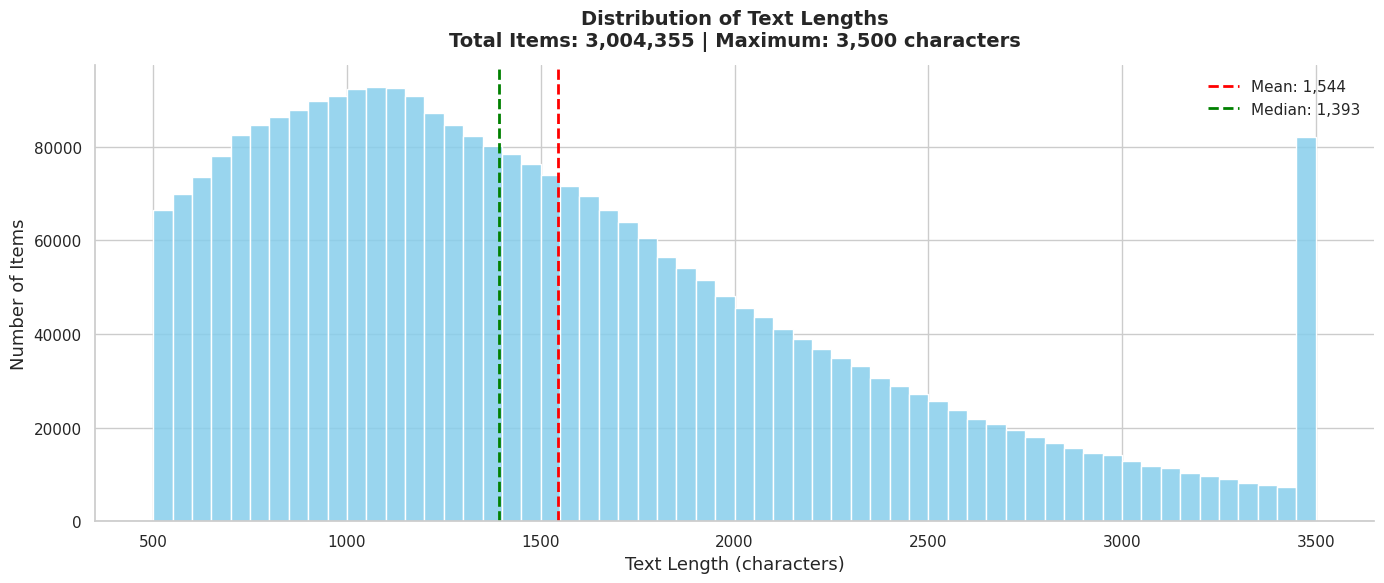

In [ ]:
# Calculate text lengths and summary statistics
lengths = [len(item.full) for item in items]

mean_length = np.mean(lengths)
median_length = np.median(lengths)
max_length = max(lengths)

# Set Seaborn theme
sns.set_theme(style="whitegrid", palette="Set2")

# Create histogram
fig, ax = plt.subplots(figsize=(14, 6))

sns.histplot(
    lengths,
    binwidth=50,
    color="skyblue",
    edgecolor="white",
    alpha=0.85,
    ax=ax
)

# Add mean and median reference lines
ax.axvline(
    mean_length,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {mean_length:,.0f}"
)

ax.axvline(
    median_length,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_length:,.0f}"
)

# Labels and formatting
ax.set_title(
    f"Distribution of Text Lengths\n"
    f"Total Items: {len(lengths):,} | Maximum: {max_length:,} characters",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.set_xlabel("Text Length (characters)", fontsize=13)
ax.set_ylabel("Number of Items", fontsize=13)

ax.legend(frameon=False, fontsize=11)
sns.despine()
plt.tight_layout()
plt.show()

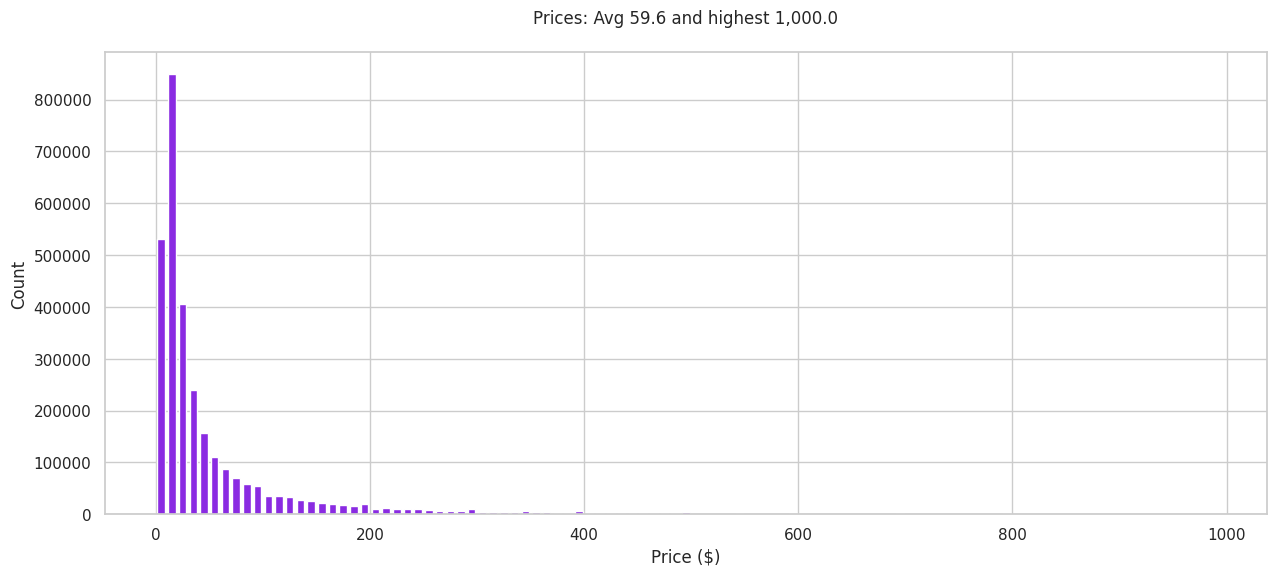

In [ ]:
# Plot the distribution of prices
prices = [item.price for item in items]
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.1f} and highest {max(prices):,}\n")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
plt.show()

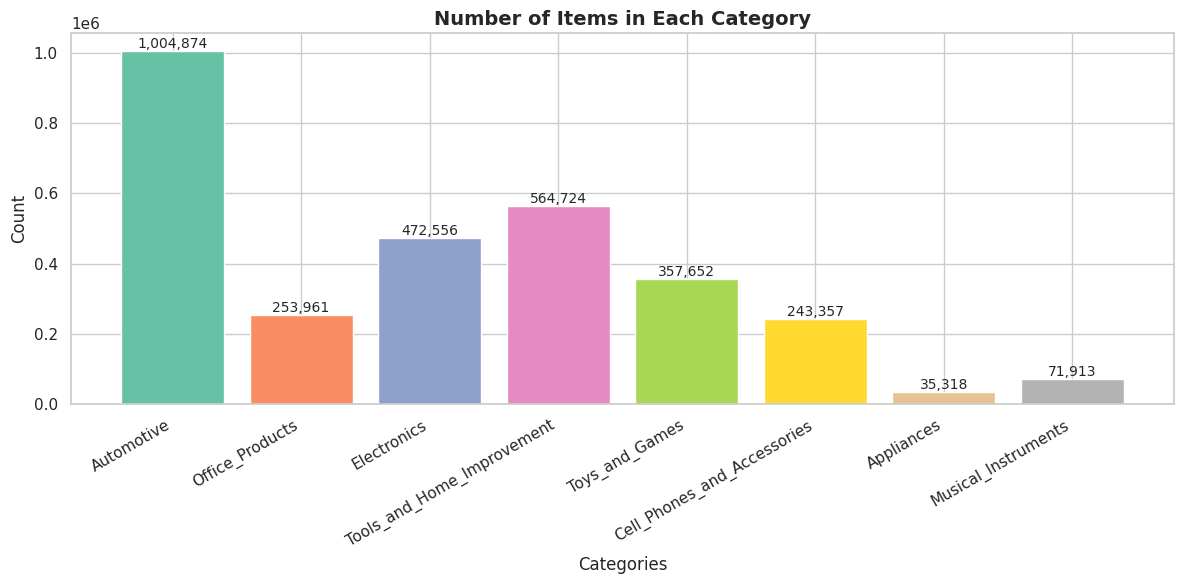

In [ ]:
# Count items in each category
category_counts = Counter(item.category for item in items)

# Extract categories and their counts
categories = list(category_counts.keys())
counts = list(category_counts.values())

# Create the bar chart
plt.figure(figsize=(12, 6))

colors = sns.color_palette("Set2", n_colors=len(categories))
plt.bar(categories, counts, color=colors)

plt.title("Number of Items in Each Category", fontsize=14, fontweight="bold")
plt.xlabel("Categories", fontsize=12, fontfamily="Verdana")
plt.ylabel("Count", fontsize=12, fontfamily="Verdana")
plt.xticks(rotation=30, ha="right")

# Display count above each bar
for i, count in enumerate(counts):
    plt.text(i, count, f"{count:,}", ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()

In [ ]:
np.random.seed(42)

SIZE = 820_000

prices = np.array([it.price for it in items], dtype=float)
categories = np.array([it.category for it in items])
p = (prices - prices.min()) / (prices.max() - prices.min() + 1e-9)

w = p**2
w[categories == "Tools_and_Home_Improvement"] *= 0.5
w[categories == "Automotive"] *= 0.05

w = w / w.sum()
idx = np.random.choice(len(items), size=SIZE, replace=False, p=w)
sample = [items[i] for i in idx]

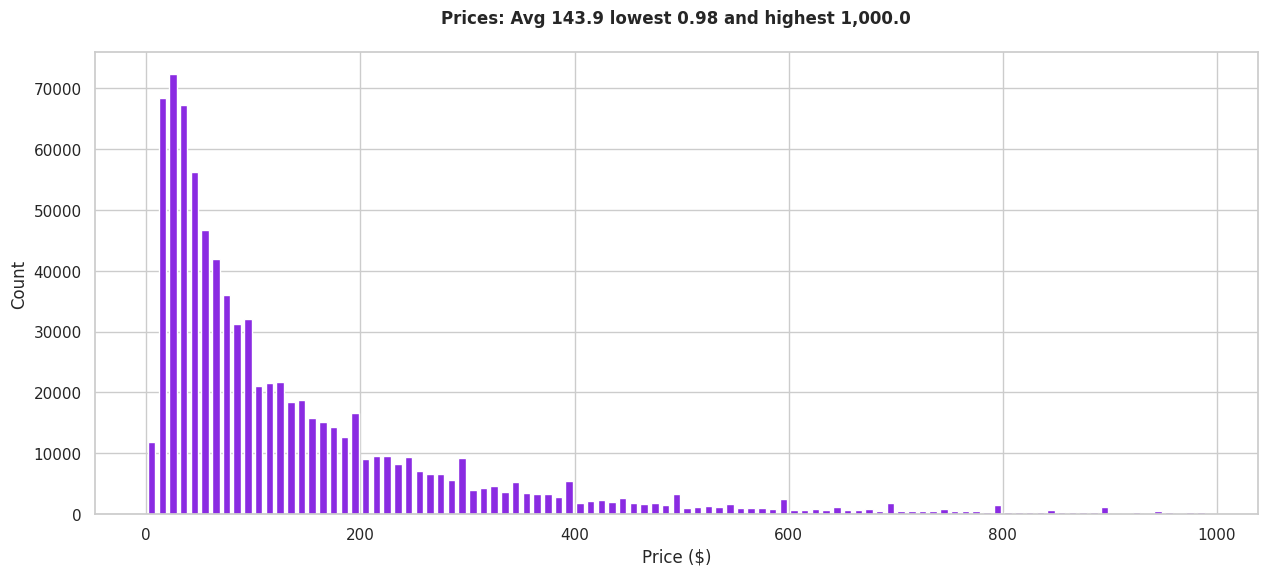

In [ ]:
prices = [item.price for item in sample]
plt.figure(figsize=(15, 6))
plt.title(f"Prices: Avg {sum(prices)/len(prices):,.1f} lowest {min(prices):,} and highest {max(prices):,}\n", fontweight="bold")
plt.xlabel('Price ($)')
plt.ylabel('Count')
plt.hist(prices, rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
plt.show()

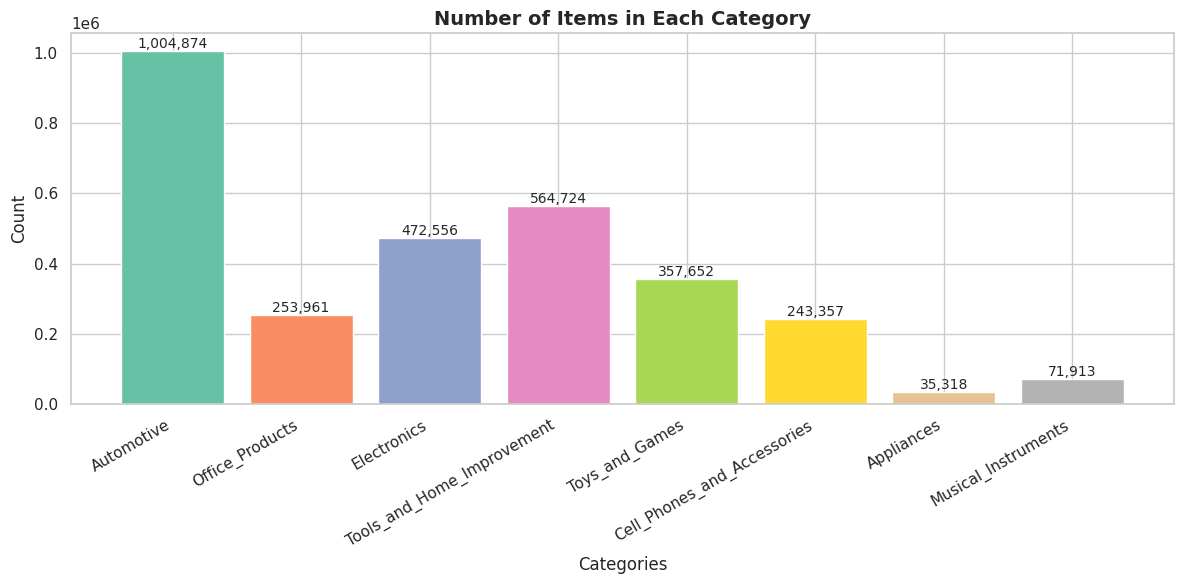

In [ ]:
# Count items in each category
category_counts = Counter(item.category for item in items)

# Extract categories and their counts
categories = list(category_counts.keys())
counts = list(category_counts.values())

# Create the bar chart
plt.figure(figsize=(12, 6))

colors = sns.color_palette("Set2", n_colors=len(categories))
plt.bar(categories, counts, color=colors)

plt.title("Number of Items in Each Category", fontsize=14, fontweight="bold")
plt.xlabel("Categories", fontsize=12, fontfamily="Verdana")
plt.ylabel("Count", fontsize=12, fontfamily="Verdana")
plt.xticks(rotation=30, ha="right")

# Display count above each bar
for i, count in enumerate(counts):
    plt.text(i, count, f"{count:,}", ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()

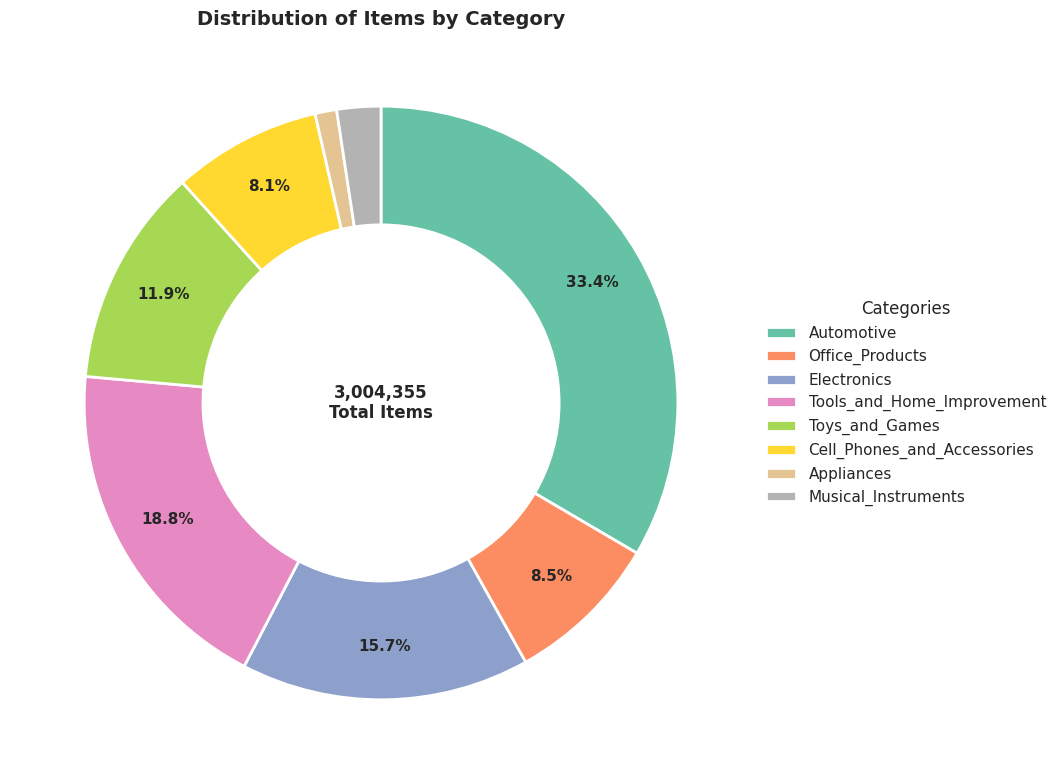

In [ ]:
# Set Seaborn theme and color palette
sns.set_theme(style="white")
colors = sns.color_palette("Set2", n_colors=len(categories))

# Create donut chart
fig, ax = plt.subplots(figsize=(12, 8))

wedges, texts, autotexts = ax.pie(
    counts,
    colors=colors,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 3 else "",
    startangle=90,
    counterclock=False,
    pctdistance=0.82,
    wedgeprops={"width": 0.4, "edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11}
)

# Improve percentage labels
plt.setp(autotexts, fontsize=11, weight="bold")

# Add center text
ax.text(
    0, 0,
    f"{sum(counts):,}\nTotal Items",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold"
)

# Add legend
ax.legend(
    wedges,
    categories,
    title="Categories",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    frameon=False
)

ax.set_title(
    "Distribution of Items by Category",
    fontsize=14,
    fontweight="bold",
    pad=5
)

ax.set_aspect("equal")
plt.tight_layout()
plt.show()

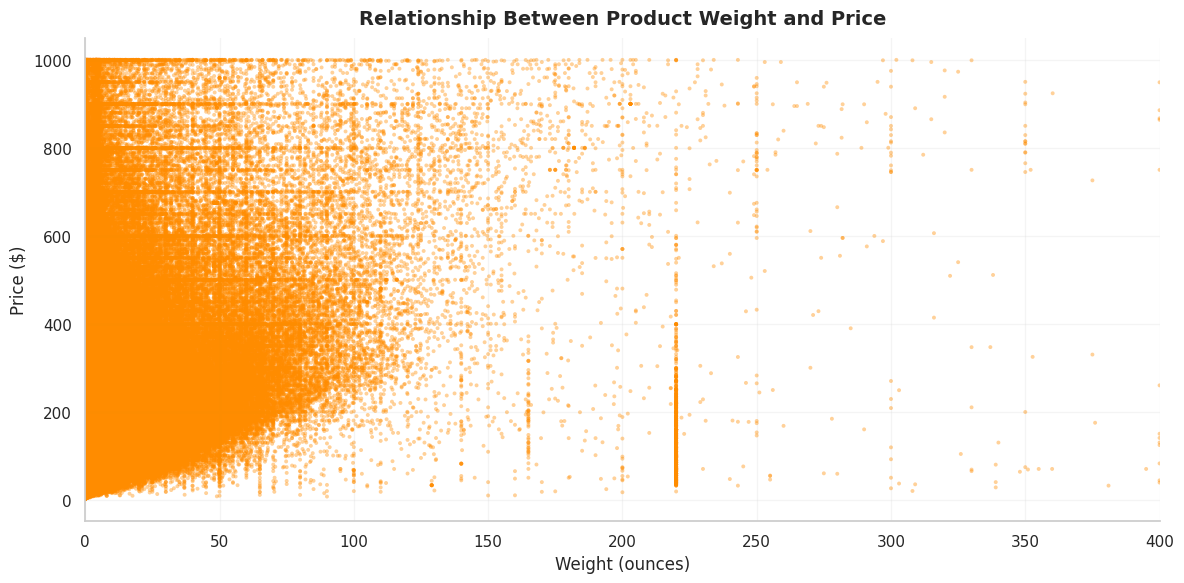

In [ ]:
# How does the price vary with the weight?
ounces = [item.weight for item in sample]
prices = [item.price for item in sample]

# Set Seaborn style
sns.set_theme(style="whitegrid")

# Create the scatter plot
plt.figure(figsize=(12, 6))
plt.scatter(ounces, prices, s=8, color="darkorange", alpha=0.4, edgecolors="none")

# Add labels and title
plt.xlabel("Weight (ounces)", fontsize=12)
plt.ylabel("Price ($)", fontsize=12)
plt.xlim(0, 400)
plt.title("Relationship Between Product Weight and Price",
          fontsize=14, fontweight="bold", pad=10)

# Improve appearance
plt.grid(alpha=0.2)
sns.despine()
plt.tight_layout()

# Display the plot
plt.show()

In [ ]:
# Just for good measure, let's shuffle the sample again for the final dataset
random.seed(42)
random.shuffle(sample)

In [ ]:
random.seed(42)
random.shuffle(items)

seen = set()
items = [x for x in tqdm(items) if not (x.title in seen or seen.add(x.title))]

seen = set()
items = [x for x in tqdm(items) if not (x.full in seen or seen.add(x.full))]

del seen
print(f"After deduplication, we have {len(items):,} items")

  0%|          | 0/2933577 [00:00<?, ?it/s]

  0%|          | 0/2889429 [00:00<?, ?it/s]

After deduplication, we have 2,887,890 items


Let's create two versions of the dataset and push them to our HuggingFace Hub repository.

In [ ]:
username = "sadjei65320"
full = f"{username}/items_raw_full"
lite = f"{username}/items_raw_lite"

train = sample[:800_000]
val = sample[800_000:810_000]
test = sample[810_000:]

Item.push_to_hub(full, train, val, test)
---------------------------------------------------------------------------

train_lite = train[:20_000]
val_lite = val[:1_000]
test_lite = test[:1_000]

Item.push_to_hub(lite, train_lite, val_lite, test_lite)

Uploading the dataset shards:   0%|          | 0/3 [00:00<?, ? shards/s]

Creating parquet from Arrow format:   0%|          | 0/5 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmphhwok21f.parquet    :   0%|          |  524kB /  267MB            

...

Creating parquet from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /tmp/tmp7o0mmt6b.parquet    : 100%|##########| 1.03MB / 1.03MB            

Validating                    :           |   0%            